<a href="https://colab.research.google.com/github/anikag2601/Science-of-Formulation-coursework/blob/main/Kishanthan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Upload the supplied kinetic CSV:


Saving SoF-Coursework-26-27-KineticData.csv to SoF-Coursework-26-27-KineticData.csv


,Supersaturation [-],Growth rate [μm s^{-1}],Nucleation rate [s^{-1} kg^{-1}]
0,1.00,0.000000,0.0
1,1.05,0.000044,0.0
2,1.10,0.023343,0.0
3,1.15,0.219017,0.0
4,1.20,0.719516,0.0


41 measurements; S range = 1.00-3.00
Absolute G fit: k1=25.4139 μm/s, k2=1.31949, RMSE=1.338 μm/s, log RMSE=1.671
Log G fit: k1=0.145967 μm/s, k2=6.57554, RMSE=30.54 μm/s, log RMSE=6.849
J fit: A=1.4e+08 1/(kg s), B=10, log RMSE=3.237e-06
Selected growth fit: absolute; k1=25.4139, k2=1.319493
Initial seed number: 218,665 per kg solvent
Reference solubility: 5.77428 g/kg
Reference initial supersaturation: 1.38546
Reference summary (95% recovery endpoint):


,Value
c0_g_kg,8.0
temperature_C,15.0
S0,1.385455
recovery_reached,True
batch_time_s,28.114794
net_mass_g,2.114439
mean_length_um,146.803944
productivity_g_h,270.746383
fixed_24h_productivity_g_h,0.092739
final_recovery_fraction,0.95


Reference at 24h:


,time_s,concentration_g_kg,crystal_mass_g,mean_length_um
500,86400.0,5.774275,3.225725,148.547942


31 eligible conditions out of 35 grid points.
Highest productivity eligible grid points (not global optimum):


,temperature_C,c0_g_kg,S0,batch_time_s,net_mass_g,mean_length_um,productivity_g_h,fixed_24h_productivity_g_h
6,5.0,12.0,2.97574,6.40458,7.56902,201.31808,4254.53230,0.33197
5,5.0,11.0,2.72776,7.19757,6.61902,197.24924,3310.63142,0.29031
13,10.0,12.0,2.48679,8.90623,6.81578,199.79842,2755.01626,0.29894
4,5.0,10.0,2.47979,8.19330,5.66902,189.47380,2490.87429,0.24864
12,10.0,11.0,2.27956,10.09526,5.86578,191.41649,2091.75657,0.25727
3,5.0,9.0,2.23181,9.51565,4.71902,180.04454,1785.32110,0.20697
20,15.0,12.0,2.07818,12.70611,5.91444,191.87700,1675.72770,0.25941
11,10.0,10.0,2.07233,11.66711,4.91578,182.10106,1516.81251,0.21560
19,15.0,11.0,1.90500,14.66754,4.96444,182.60203,1218.47144,0.21774
2,5.0,8.0,1.98383,11.37528,3.76902,169.40129,1192.80451,0.16531


No PBE file supplied: actual model comparison is pending.


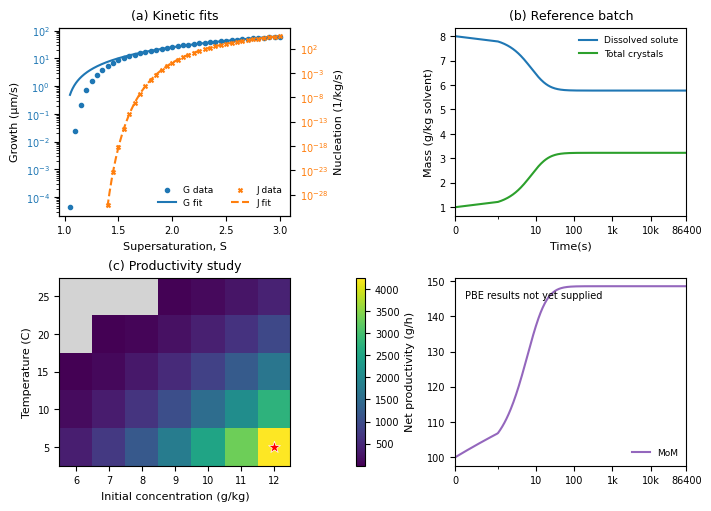

Saved figure, fitted parameters, reference results and productivity study to the working directory.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.integrate import solve_ivp
from pathlib import Path
from IPython.display import display

CSV_NAME = 'SoF-Coursework-26-27-KineticData.csv'
if not Path(CSV_NAME).exists():
  try:
    from google.colab import files
    print('Upload the supplied kinetic CSV:')
    uploaded = files.upload()
    if CSV_NAME not in uploaded:
      raise FileNotFoundError(f'Please upload {CSV_NAME}')
  except ImportError:
    raise FileNotFoundError(f'Place {CSV_NAME} in the working directory.')

data = pd.read_csv(CSV_NAME)
S_data, G_data, J_data = data.iloc[:, :3].to_numpy(dtype=float).T
assert np.all(np.isfinite(data.iloc[:, :3].to_numpy(dtype=float)))
assert np.all(S_data >=1) and np.all(G_data >= 0) and np.all(J_data >= 0)
display(data.head())
print(f'{len(data)} measurements; S range = {S_data.min():.2f}-{S_data.max():.2f}')

def growth_laws(S, k1, k2):
    return k1 * np.maximum(np.asarray(S) - 1.0, 0.0)**k2

def nucleation_laws(S, A, B):
    # Avoid log(1) and undefined values for undersaturated liquid.
    S = np.asarray(S, dtype=float)
    lnS = np.log(np.maximum(S, 1e-12))
    return np.where(S > 1, A * np.exp(-B / lnS**2), 0.0)

# Absolute-error fit for G; include the zero at S=1.
(k1_raw, k2_raw), _ = curve_fit(growth_laws, S_data, G_data, p0=[25, 1.5], bounds=(0, np.inf))
# Alternative log-error growth fit (for sensitivity only).
mg = (S_data > 1) & (G_data > 0)
k2_log, log_k1 = np.polyfit(np.log(S_data[mg]), np.log(G_data[mg]), 1)
k1_log = np.exp(log_k1)

# Log-linear least squares for J; positive measured rates only.
mj = (S_data > 1) & (J_data > 0)
slope, intercept = np.polyfit(1 / np.log(S_data[mj])**2, np.log(J_data[mj]), 1)
A, B = np.exp(intercept), -slope
assert B > 0

GROWTH_FIT = 'absolute' # change to 'log' and return all later cells for sensitivity
k1, k2 = (k1_raw, k2_raw) if GROWTH_FIT == 'absolute' else (k1_log, k2_log)

def rmse(y, yhat):
    return np.sqrt(np.mean((np.asarray(y) - np.asarray(yhat))**2))

for name, a, b in [('Absolute', k1_raw, k2_raw), ('Log', k1_log, k2_log)]:
    pred = growth_laws(S_data, a, b)
    print(f'{name} G fit: k1={a:.6g} μm/s, k2={b:.6g}, '
          f'RMSE={rmse(G_data, pred):.4g} μm/s, '
          f'log RMSE={rmse(np.log(G_data[mg]), np.log(pred[mg])):.4g}')
print(f'J fit: A={A:.7g} 1/(kg s), B={B:.7g}, '
      f'log RMSE={rmse(np.log(J_data[mj]), np.log(nucleation_laws(S_data[mj], A, B))):.4g}')
print(f'Selected growth fit: {GROWTH_FIT}; k1={k1:.7g}, k2={k2:.7g}')

pd.DataFrame([dict(k1=k1, k2=k2, A=A, B=B, growth_fit=GROWTH_FIT)]).to_csv('Kinetic_parameters.csv', index=False)

# Reference conditions from Table 1
C0_REF = 8.0 # g/kg solvent
T_REF = 15.0 # deg C
SEED_MEAN = 100.0 # μm
SEED_SD = 10.0 # μm
SEED_MASS = 1.0 # g (total seed mass)
SOLVENT_KG = 1.0 # assumed basis, not given in brief
RHO = 1.11e-12 # g/μm^3
KV = 4.0 # dimensionless
L_MAX = 500.0 # μm
T_MAX = 86400.0 # s
L_REF = SEED_MEAN

# Batch seed mass converted to g/kg; moments are per kg of solvent.
seed_raw = np.array([1.0, SEED_MEAN, SEED_MEAN**2 + SEED_SD**2,
                     SEED_MEAN**3 + 3 * SEED_MEAN * SEED_SD**2])
N_REF = (SEED_MASS / SOLVENT_KG) / (RHO * KV * seed_raw[3])
scales = N_REF * L_REF**np.arange(4)
initial_q = N_REF * seed_raw / scales
mass_scale = RHO * KV * scales[3]

def solubility(T):
    return 3.37 * np.exp(0.0359 * np.asarray(T))

def rhs(t, y, T):
    q0, q1, q2, q3, c = y
    S = c / solubility(T)
    G = float(growth_laws(S, k1, k2))
    J = float(nucleation_laws(S, A, B))
    g = G / L_REF
    dq3 = 3 * g * q2
    return [J / N_REF, g * q0, 2 * g * q1, dq3, -mass_scale * dq3]

def simulate(c0, T, tmax=T_MAX, recovery=0.95, points=500):
    """Isothermal batch; recovery refers to fraction of initially recoverable solute."""
    cs = float(solubility(T))
    if c0 <= cs:
        raise ValueError('Initially undersaturated/saturated; no growth-only batch model.')
    if c0 / cs > S_data.max() + 1e-5:
        raise ValueError('Initial S exceeds measured kinetics range.')
    if not 0 < recovery < 1:
        raise ValueError('Recovery must be between zero and one.')
    y0 = np.r_[initial_q, c0]
    c_goal = c0 - recovery * (c0 - cs)

    def event(t, y):
        return y[4] - c_goal
    event.direction = -1
    event.terminal = False # still integrate the entire reference batch

    sol = solve_ivp(lambda t, y: rhs(t, y, T), (0, tmax), y0, method='BDF', rtol=1e-8, atol=1e-10, dense_output=True, events=event)
    if not sol.success:
        raise RuntimeError(sol.message)

    # Log-spaced early time captures rapid kinetics, plus full 24 h endpoint.
    times = np.unique(np.r_[0., np.geomspace(min(0.01, tmax), tmax, points - 1), sol.t_events[0]])
    y = sol.sol(times)
    M = y[:4, :] * scales[:, None]
    mass_per_kg = RHO * KV * M[3]

    result = pd.DataFrame(dict(
        time_s=times,
        concentration_g_kg=y[4],
        supersaturation=y[4] / cs,
        crystal_mass_g=mass_per_kg * SOLVENT_KG,
        mean_length_um=M[1] / M[0],
        M1=M[1],
        M2=M[2],
        M3=M[3]
    ))
    result['net_crystal_mass_g'] = result.crystal_mass_g - SEED_MASS

    # Check solute conservation: initial dissolved plus seed mass = final total.
    balance_error = np.max(np.abs(result.concentration_g_kg + mass_per_kg - (c0 + SEED_MASS / SOLVENT_KG)))
    if balance_error > 1e-6 or np.any(y[4] < cs - 1e-6) or np.any(y[:4] < -1e-9):
        raise RuntimeError('Mass balance or non-negativity check failed.')

    reached = len(sol.t_events[0]) > 0
    end_time = float(sol.t_events[0][0]) if reached else float(tmax)
    end_q = sol.sol(end_time)
    net_mass = (mass_scale * end_q[3]) * SOLVENT_KG - SEED_MASS

    summary = dict(
        c0_g_kg=c0,
        temperature_C=T,
        S0=c0 / cs,
        recovery_reached=reached,
        batch_time_s=end_time,
        net_mass_g=net_mass,
        mean_length_um=L_REF * end_q[1] / end_q[0],
        productivity_g_h=net_mass / (end_time / 3600),
        fixed_24h_productivity_g_h=result.net_crystal_mass_g.iloc[-1] / (tmax / 3600),
        final_recovery_fraction=(c0 - end_q[4]) / (c0 - cs),
        max_mass_balance_error_g_kg=balance_error
    )
    return result, summary

ref, ref_summary = simulate(C0_REF, T_REF)
print(f'Initial seed number: {N_REF:,.0f} per kg solvent')
print(f'Reference solubility: {solubility(T_REF):.5f} g/kg')
print(f'Reference initial supersaturation: {ref_summary["S0"]:.5f}')
print('Reference summary (95% recovery endpoint):')
display(pd.DataFrame([ref_summary]).T.rename(columns={0: 'Value'}))
print('Reference at 24h:')
display(ref.iloc[[-1]][['time_s', 'concentration_g_kg', 'crystal_mass_g', 'mean_length_um']])
ref.to_csv('mom_reference.csv', index=False)

TEMPERATURES = np.arange(5., 26., 5.) # degrees C
CONCENTRATIONS = np.arange(6., 12.1, 1.) # g/kg
RECOVERY_TARGET = 0.95
TARGET_SIZE_RANGE_UM = None

records = []
for T in TEMPERATURES:
    for c0 in CONCENTRATIONS:
        S0 = c0 / solubility(T)
        if not 1 < S0 <= S_data.max() + 1e-5:
            records.append(dict(
                temperature_C=T, c0_g_kg=c0, S0=S0,
                recovery_reached=False, feasible=False,
                status='outside kinetic range or not supersaturated'
            ))
            continue
        _, row = simulate(c0, T, recovery=RECOVERY_TARGET, points=120)
        size_ok = (TARGET_SIZE_RANGE_UM is None or TARGET_SIZE_RANGE_UM[0] <= row['mean_length_um'] <= TARGET_SIZE_RANGE_UM[1])
        row['feasible'] = bool(row['recovery_reached'] and size_ok)
        row['status'] = 'eligible' if row['feasible'] else 'recovery or size criterion not met'
        records.append(row)
study = pd.DataFrame(records)
assert study.productivity_g_h.notna().any()
ranked = study[study.feasible].sort_values('productivity_g_h', ascending=False)
cols = ['temperature_C', 'c0_g_kg', 'S0', 'batch_time_s', 'net_mass_g', 'mean_length_um', 'productivity_g_h', 'fixed_24h_productivity_g_h']
print(f'{len(ranked)} eligible conditions out of {len(study)} grid points.')
if ranked.empty:
    print('No conditions satisfy the selected criteria. Revise the study, not the data.')
else:
    print('Highest productivity eligible grid points (not global optimum):')
    display(ranked[cols].head(10).round(5))
study.to_csv('productivity_study.csv', index=False)

UPLOAD_PBE = False
PBE_PATH = Path('pbe_reference.csv')
if UPLOAD_PBE and not PBE_PATH.exists():
    from google.colab import files
    files.upload()

pbe = None
if PBE_PATH.exists():
    pbe = pd.read_csv(PBE_PATH).sort_values('time_s')
    required = ['time_s', 'concentration_g_kg', 'crystal_mass_g', 'mean_length_um']
    if not set(required).issubset(pbe.columns):
        raise ValueError(f'PBE CSV must contain {required}')
    if len(pbe) < 2 or not np.isfinite(pbe[required].to_numpy()).all() or pbe.time_s.duplicated().any():
        raise ValueError('PBE data must contain at least two distinct finite time points.')
    if pbe.time_s.min() < 0 or pbe.time_s.max() > T_MAX + 1e-6:
        raise ValueError('PBE time must be within 0-86400 s.')

    rows = []
    for name in required[1:]:
        mom_values = np.interp(pbe.time_s, ref.time_s, ref[name])
        error = pbe[name].to_numpy() - mom_values
        rows.append(dict(variable=name, RMSE=np.sqrt(np.mean(error**2)), max_abs_error=np.max(np.abs(error))))
    display(pd.DataFrame(rows))
    if not np.isclose(pbe.time_s.iloc[0], 0) or not np.isclose(pbe.time_s.iloc[-1], T_MAX):
        print('Warning: PBE does not cover the entire reference interval.')
    if np.isclose(pbe.time_s.iloc[0], 0):
        print('PBE initial mass, c, mean length:', pbe[required[1:]].iloc[0].to_dict())
else:
    print('No PBE file supplied: actual model comparison is pending.')

from matplotlib.ticker import FuncFormatter
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 8, 'axes.titlesize': 9,
    'axes.labelsize': 8, 'legend.fontsize': 6.5, 'xtick.labelsize': 7, 'ytick.labelsize': 7
})
fig, axs = plt.subplots(2, 2, figsize=(7, 5), layout='constrained')
ax = axs[0, 0]
ss = np.linspace(1.05, S_data.max(), 500)
ax.scatter(S_data[mg], G_data[mg], s=9, color='tab:blue', label='G data')
ax.plot(ss, growth_laws(ss, k1, k2), color='tab:blue', label='G fit')
ax.set(yscale='log', xlabel='Supersaturation, S', ylabel='Growth (μm/s)', title='(a) Kinetic fits')
ax.tick_params(axis='y', labelcolor='tab:blue')
axj = ax.twinx()
axj.scatter(S_data[mj], J_data[mj], s=8, marker='x', color='tab:orange', label='J data')
js = nucleation_laws(ss, A, B)
show = js >= J_data[mj].min() / 10
axj.plot(ss[show], js[show], color='tab:orange', ls='--', label='J fit')
axj.set(yscale='log', ylabel='Nucleation (1/kg/s)')
axj.tick_params(axis='y', labelcolor='tab:orange')
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = axj.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='lower right', ncol=2, frameon=False)

ax = axs[0, 1]
ax.plot(ref.time_s, ref.concentration_g_kg, color='tab:blue', label='Dissolved solute')
ax.plot(ref.time_s, ref.crystal_mass_g / SOLVENT_KG, label='Total crystals', color='tab:green')
if pbe is not None:
    ax.plot(pbe.time_s, pbe.concentration_g_kg, ls='--', color='tab:blue', label='PBE liquid')
    ax.plot(pbe.time_s, pbe.crystal_mass_g / SOLVENT_KG, ls='--', color='tab:green', label='PBE solid')
ax.set(xlabel='Time(s)', ylabel='Mass (g/kg solvent)', title='(b) Reference batch')
ax.set_xscale('symlog', linthresh=1)
ax.set_xlim(0, T_MAX)
ax.legend(frameon=False)

ax = axs[1, 0]
plot_data = study.assign(plot_productivity=study.productivity_g_h.where(study.feasible))
heat = plot_data.pivot(index='temperature_C', columns='c0_g_kg', values='plot_productivity').reindex(index=TEMPERATURES, columns=CONCENTRATIONS)
cm = plt.get_cmap('viridis').copy()
cm.set_bad('lightgrey')
im = ax.imshow(np.ma.masked_invalid(heat.to_numpy()), origin='lower', aspect='auto', cmap=cm, extent=[CONCENTRATIONS[0] - 0.5, CONCENTRATIONS[-1] + 0.5, TEMPERATURES[0] - 2.5, TEMPERATURES[-1] + 2.5])
fig.colorbar(im, ax=ax, label='Net productivity (g/h)')
ax.set(xlabel='Initial concentration (g/kg)', ylabel='Temperature (C)', title='(c) Productivity study')
ax.set_xticks(CONCENTRATIONS)
ax.set_yticks(TEMPERATURES)
if not ranked.empty:
    best = ranked.iloc[0]
    ax.scatter(best.c0_g_kg, best.temperature_C, marker='*', s=80, color='red', edgecolors='white', linewidths=0.5)

ax = axs[1, 1]
ax.plot(ref.time_s, ref.mean_length_um, label='MoM', color='tab:purple')
if pbe is not None:
    ax.plot(pbe.time_s, pbe.mean_length_um, label='Semi-discrete PBE', color='tab:black', ls='--')
else:
    ax.text(0.04, 0.93, 'PBE results not yet supplied', transform=ax.transAxes, va='top', fontsize=7)
ax.set_xscale('symlog', linthresh=1)
ax.set_xlim(0, T_MAX)
ax.legend(frameon=False, loc='lower right')

for ax in (axs[0, 1], axs[1, 1]):
    ax.set_xticks([0, 10, 100, 1000, 10000, 86400])
    ax.set_xticklabels(['0', '10', '100', '1k', '10k', '86400'])
fig.savefig('optimus_four_panel.png', dpi=300)
fig.savefig('optimus_four_panel.pdf')
plt.show()
print('Saved figure, fitted parameters, reference results and productivity study to the working directory.')